# 05 - Wizualizacja z `pyplot`

## Rozdziały 5-6-7

- W kolejnych rozdziałach zagłębimy się w **wizualizację danych**.  
  - Jak tworzyć wizualizacje w Pythonie?
  - O jakich zasadach powinniśmy pamiętać?
  - Jak współpracować z Matplotlib, Pyplot?
  - Jak pracować nad wizualizacjami w Seaborn? 
  - Jakie są dobre praktyki tworzenia wizualizacji danych?
- Następnie, zanim przystąpi do analizy statystycznej, będziemy pracować nad **zarządzaniem** i **czyszczeniem** naszych danych.
  - Jak radzić sobie z *brakującymi wartościami*?
  - Jak sobie poradzić z *brudnymi danymi*?
  - Jakie są podstawowe sposoby *opisywania* danych?
  
Pamiętajcie, ze te rozdziały to integralna część **Eksploracyjnej Analizy Danych** w Pythonie.

## W tym rozdziale

- Czym *jest* wizualizacja danych i dlaczego jest ważna?
- Wprowadzenie do `matplotlib`.
- Typy wykresów jednowymiarowych:
 - **Histogramy** (jednowymiarowe).
  - **Wykresy rozrzutu** (tzw. scatterplots - dwuwymiarowe).
  - **Wykresy słupkowe** (takze dwuwymiarowe).

## Wprowadzenie: wizualizacja danych

### Czym jest wizualizacja danych?

[Wizualizacja danych](https://en.wikipedia.org/wiki/Data_visualization) odnosi się do procesu (i wyniku) graficznego przedstawiania danych.

Dla naszych celów w tym rozdziale będziemy mówić głównie o typowych metodach **wykresów** danych, w tym:

- Histogramy 
- Wykresy punktowe 
- Wykresy liniowe
- Wykresy słupkowe

### Dlaczego wizualizacja danych jest ważna?

- Eksploracyjna analiza danych
- Przekazywanie spostrzeżeń
- Pokazywanie ukrytych asocjacji w danych

### Eksploracyjna analiza danych: Sprawdzanie założeń

[Anscombe's Quartet](https://en.wikipedia.org/wiki/Anscombe%27s_quartet)

![title](img/anscombe.png)

### Przekazywanie informacji

[Full Stack Economics](https://fullstackeconomics.com/18-charts-that-explain-the-american-economy/)

![title](img/work.png)

### Wpływ na zrozumienie świata

[Florence Nightingale](https://en.wikipedia.org/wiki/Florence_Nightingale) (1820-1910) był reformatorem społecznym, statystykiem i założycielem nowoczesnego pielęgniarstwa.

![title](img/polar.jpeg)

### Wpływ na zrozumienie świata (cz. 2)

[John Snow](https://en.wikipedia.org/wiki/John_Snow) (1813-1858) był lekarzem, którego wizualizacja ognisk cholery pomogła zidentyfikować źródło i mechanizm rozprzestrzeniania się (zaopatrzenie w wodę).

![title](img/cholera.jpeg)

## Wprowadzenie do `matplotlib`

### Ładowanie pakietów

Tutaj ładujemy podstawowe pakiety, których będziemy używać. 

Dodajemy również kilka linijek kodu, które zapewniają, że nasze wizualizacje będą wykreślane „inline” z naszym kodem i że będą miały ładną, wyraźną jakość.

In [4]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as ss
import seaborn as sborn

In [21]:
%matplotlib inline 
%config InlineBackend.figure_format = 'retina'

### Czym jest `matplotlib`?

> [`matplotlib`](https://matplotlib.org/) to **pakiet graficzny** dla Pythona.

- Wiele [tutoriali](https://matplotlib.org/stable/tutorials/index.html) dostępnych online.  
- Również wiele [przykładów](https://matplotlib.org/stable/gallery/index) `matplotlib` w użyciu.

Zauważ, że [`seaborn`](https://seaborn.pydata.org/), (który omówimy wkrótce) używa `matplotlib` „pod maską”.

### Czym jest `pyplot`?

> [`pyplot`](https://matplotlib.org/stable/tutorials/introductory/pyplot.html) to zbiór funkcji *w ramach* `matplotlib`, które naprawdę ułatwiają wykreślanie danych.

Z `pyplot`, możemy łatwo wykreślić takie rzeczy jak:

- Histogramy (`plt.hist`)
- Wykresy rozrzutu (`plt.scatter`)
- Wykresy liniowe (`plt.plot`) 
- Wykresy słupkowe (`plt.bar`)

### Przykładowe dane

Załadujmy nasz znajomy zestaw danych Pokemon, który można znaleźć w sekcji `data/pokemon.csv`.

In [5]:
df_pokemon = pd.read_csv("data/pokemon.csv")
df_pokemon.head(10)
#df_pokemon.describe
#df_pokemon.info()

,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
4,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False
5,5,Charmeleon,Fire,NaN,405,58,64,58,80,65,80,1,False
6,6,Charizard,Fire,Flying,534,78,84,78,109,85,100,1,False
7,6,CharizardMega Charizard X,Fire,Dragon,634,78,130,111,130,85,100,1,False
8,6,CharizardMega Charizard Y,Fire,Flying,634,78,104,78,159,115,100,1,False
9,7,Squirtle,Water,NaN,314,44,48,65,50,64,43,1,False


## Histogramy

### Czym są histogramy?

> **Histogram** to wizualizacja pojedynczej ciągłej zmiennej ilościowej (np. dochodu lub temperatury).

- Histogramy są przydatne do sprawdzania, jak **rozkłada się** zmienna.  
- Mogą być używane do określenia, czy rozkład jest **normalny**, **skośny** lub **bimodalny**.

Histogram jest wykresem **jednowymiarowym**, tj. wyświetla tylko jedną zmienną.

### Histogramy w `matplotlib`

Aby utworzyć histogram, wywołaj `plt.hist` z **pojedynczą kolumną** `DataFrame` (lub `numpy.ndarray`).

**Pytanie**: Co mówi nam ten wykres?

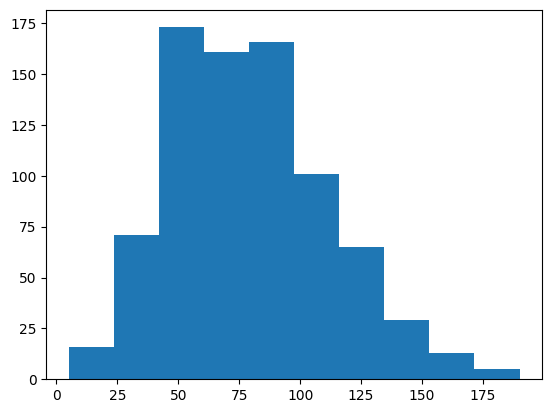

In [5]:
p = plt.hist(df_pokemon['Attack'])

#HISTOGRAM robimy dla jednej zmiennej
#maximum, minimum

#### Zmiana liczby przedziałów

Histogram umieszcza dane ciągłe w **przedziałach** (np. 1-10, 11-20 itd.).

- Wysokość każdego przedziału odzwierciedla liczbę obserwacji w tym przedziale.  
- Zwiększanie lub zmniejszanie liczby przedziałów zapewnia większą lub mniejszą szczegółowość rozkładu.

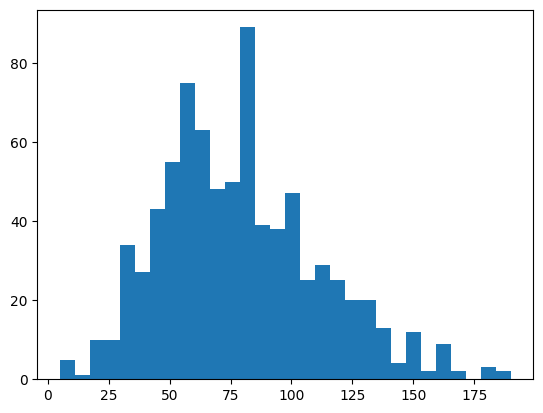

In [6]:
### Ten wykres ma wiele przedziałów - 30. 
# RSz: czyli dokładniejsze, krótsze przedziałki

p = plt.hist(df_pokemon['Attack'], bins = 30)

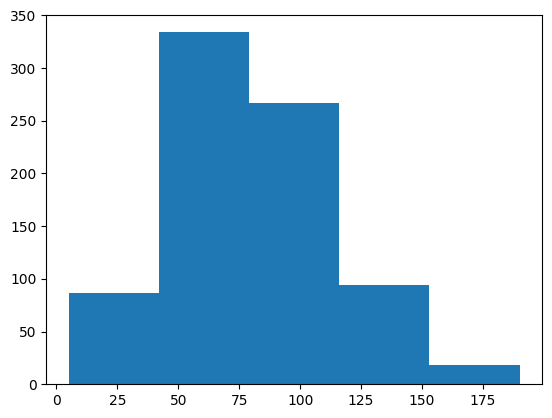

In [7]:
### Ten ma mniej
p = plt.hist(df_pokemon['Attack'], bins = 5)

#### Zmiana poziomu `alpha`

Poziom `alfa` zmienia **przezroczystość** twojego wykresu.

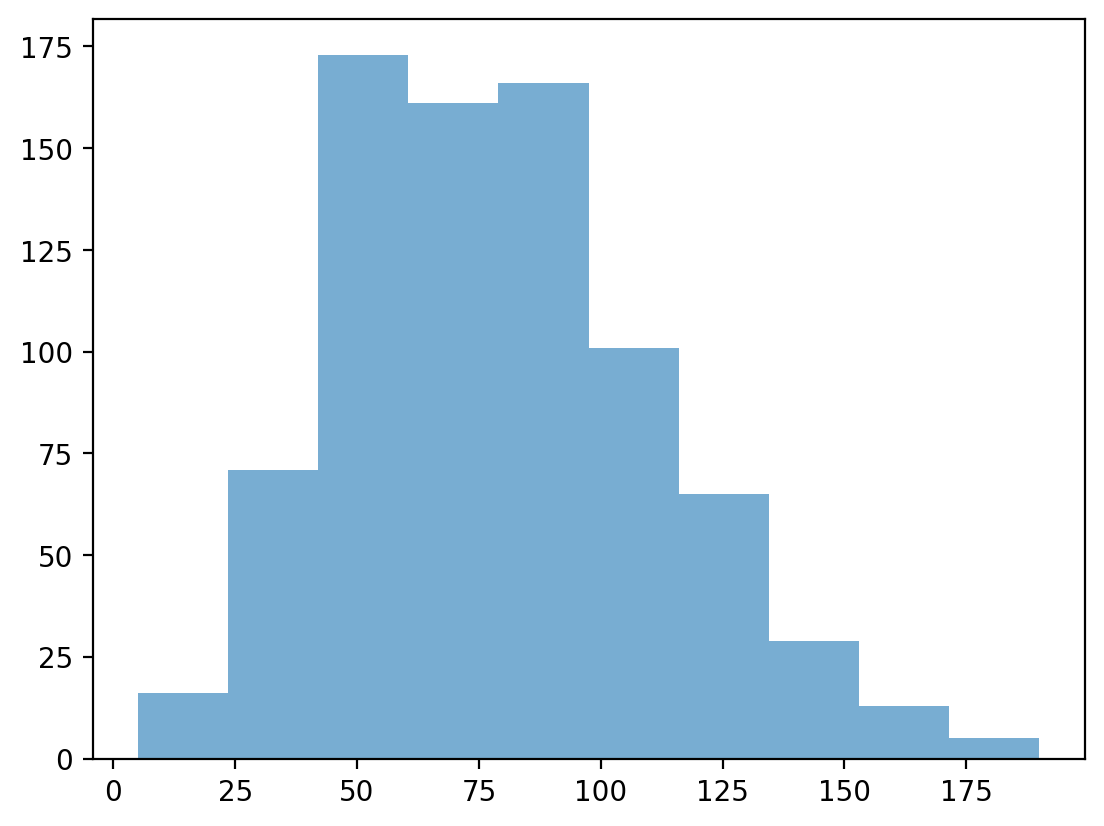

In [54]:
### ten ma mniej przedziałów - ustawiamy przeźroczystość
p = plt.hist(df_pokemon['Attack'], alpha = .6)

#### Sprawdź się

Jak stworzyć histogram wyników dla `Defense`?

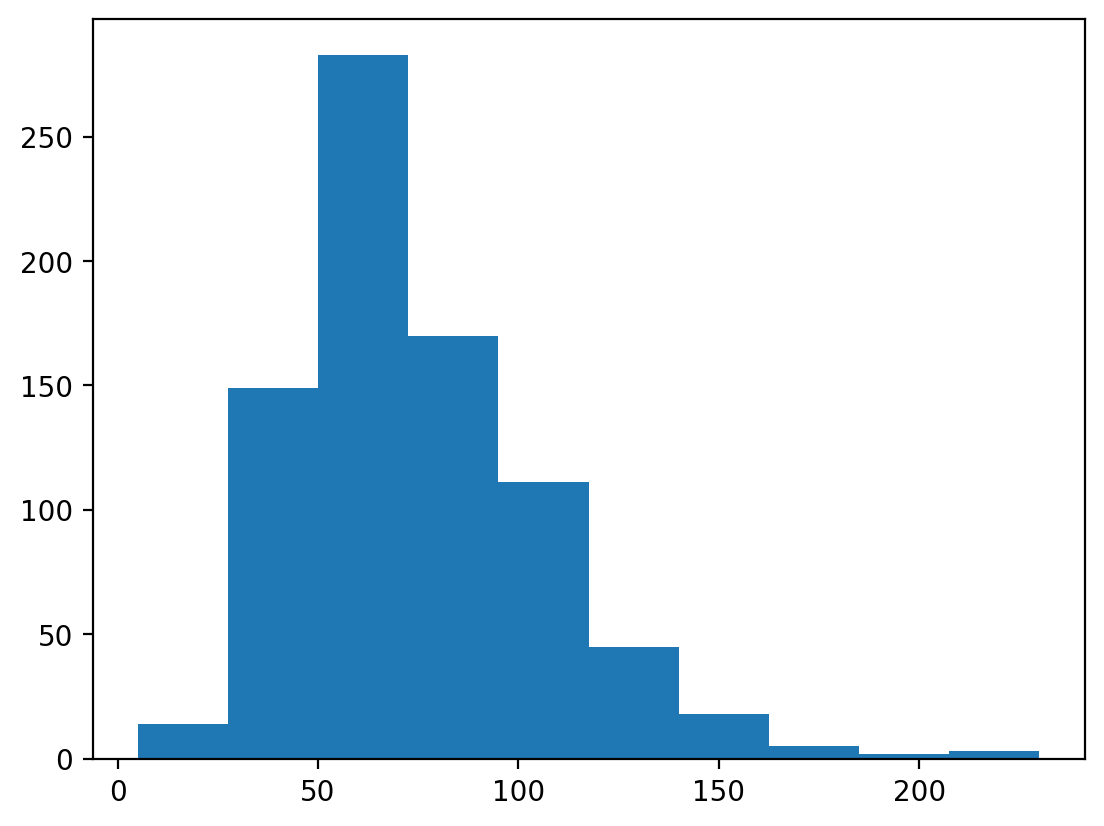

In [ ]:
#defHist = plt.hist(df_pokemon['Defense'], bins = 30)
defHist = plt.hist(df_pokemon['Defense'])
#RSz: większość ma mniej niż średnia

#### Sprawdź się

Czy wiesz jak stworzyć histogram wyników dla `Typu 1`?

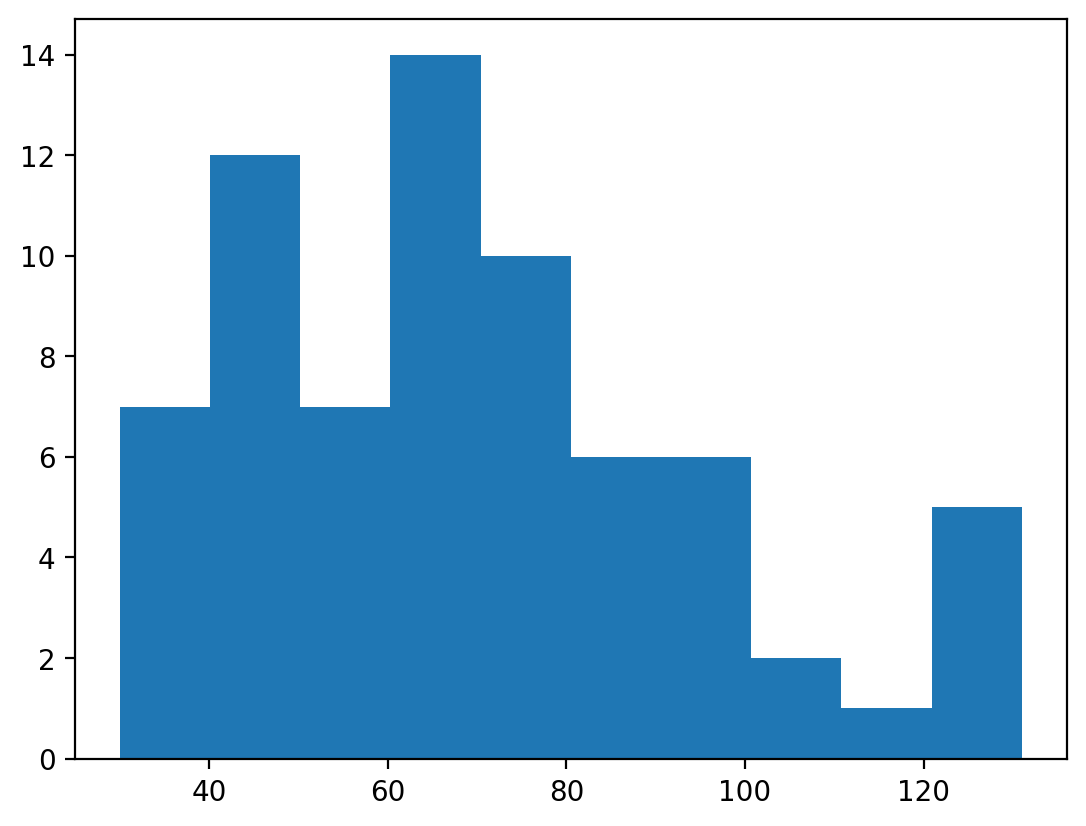

In [66]:
defHist = plt.hist(df_pokemon['Defense'].where(df_pokemon["Type 1"]=="Grass"))
#defHist = plt.hist(df_pokemon['Defense'].query('Type 1=Grass'))

### Informacja z histogramów

Histogramy są niezwykle przydatne do poznawania **kształtu** naszego rozkładu. 

Możemy zadawać pytania takie jak:

- Czy ten rozkład jest względnie [normalny](https://en.wikipedia.org/wiki/Normal_distribution)?
- Czy rozkład jest [skośny](https://en.wikipedia.org/wiki/Skewness)?
- Czy są [wartości odstające](https://en.wikipedia.org/wiki/Outlier)?

#### Dane o rozkładzie normalnym

Możemy użyć funkcji `numpy.random.normal`, aby utworzyć **rozkład normalny**, a następnie go wykreślić.

Rozkład normalny ma następujące cechy:

- Klasyczny kształt "dzwonu" (**symetryczny**).  
- Średnia, mediana i moda są identyczne.

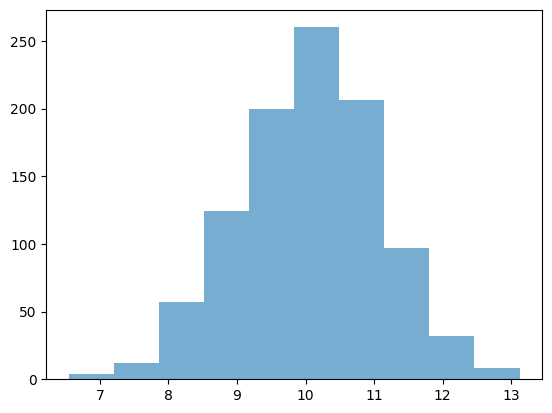

In [8]:
norm = np.random.normal(loc = 10, scale = 1, size = 1000)
#loc - średnia arytmetyczna
#scale - odchylenie standardowe 
#siza - liczba obserwacji 
#liczbę próbek można zmieniać, np. od 50 do 1000. na przestrzeni tych zmian widać jak sie zmienia wykres
p = plt.hist(norm, alpha = .6)

#### Skośne dane

> **Skośność** oznacza, że istnieją wartości *wydłużające* jeden z „ogonów” rozkładu.

- Skośność dodatnia/prawa: ogon jest skierowany w prawo.  
- Ujemny/lewy skośny: ogon jest skierowany w lewo.

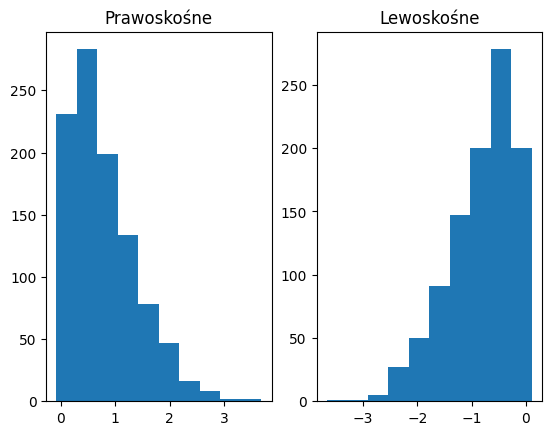

In [9]:
rskew = ss.skewnorm.rvs(20, size = 1000) # tworzymy dane prawo-skośne
lskew = ss.skewnorm.rvs(-20, size = 1000) # tworzymy dane lewo-skośne
fig, axes = plt.subplots(1, 2) #podział na dwa ekrany, tj. jeden wiersz i 2 kolumny
axes[0].hist(rskew)
axes[0].set_title("Prawoskośne");
axes[1].hist(lskew)
axes[1].set_title("Lewoskośne");

#### Punkty odstające

> **Punkty odstające** to punkty danych, które znacznie różnią się od innych punktów w rozkładzie.

- W przeciwieństwie do danych skośnych, wartości odstające są zazwyczaj **nieciągłe** w stosunku do reszty rozkładu.
- W kolejnym rozdziale omówimy więcej sposobów **identyfikacji** wartości odstających; na razie możemy polegać na histogramach.

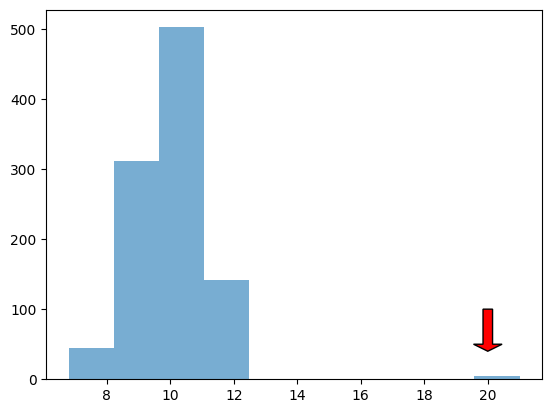

In [10]:
norm = np.random.normal(loc = 10, scale = 1, size = 1000)
upper_outliers = np.array([21, 21, 21, 21]) ## trochę odstających
data = np.concatenate((norm, upper_outliers))
p = plt.hist(data, alpha = .6)
plt.arrow(20, 100, dx = 0, dy = -50, width = .3, head_length = 10, facecolor = "red");

#tu warto było zastosować skalę logarytmiczną...chyba, że przypadki odstające są niemożliwe to je usuwamy

#### Sprawdź się

Jak opiszesz następujący rozkład?

- Normalny czy skośny?  
- Z wartościami odstającymi czy bez?

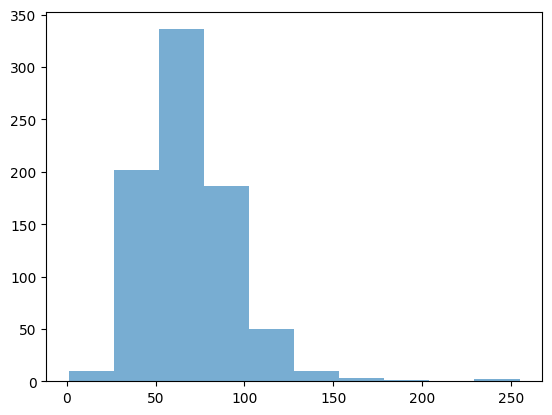

In [11]:
p = plt.hist(df_pokemon['HP'], alpha = .6)

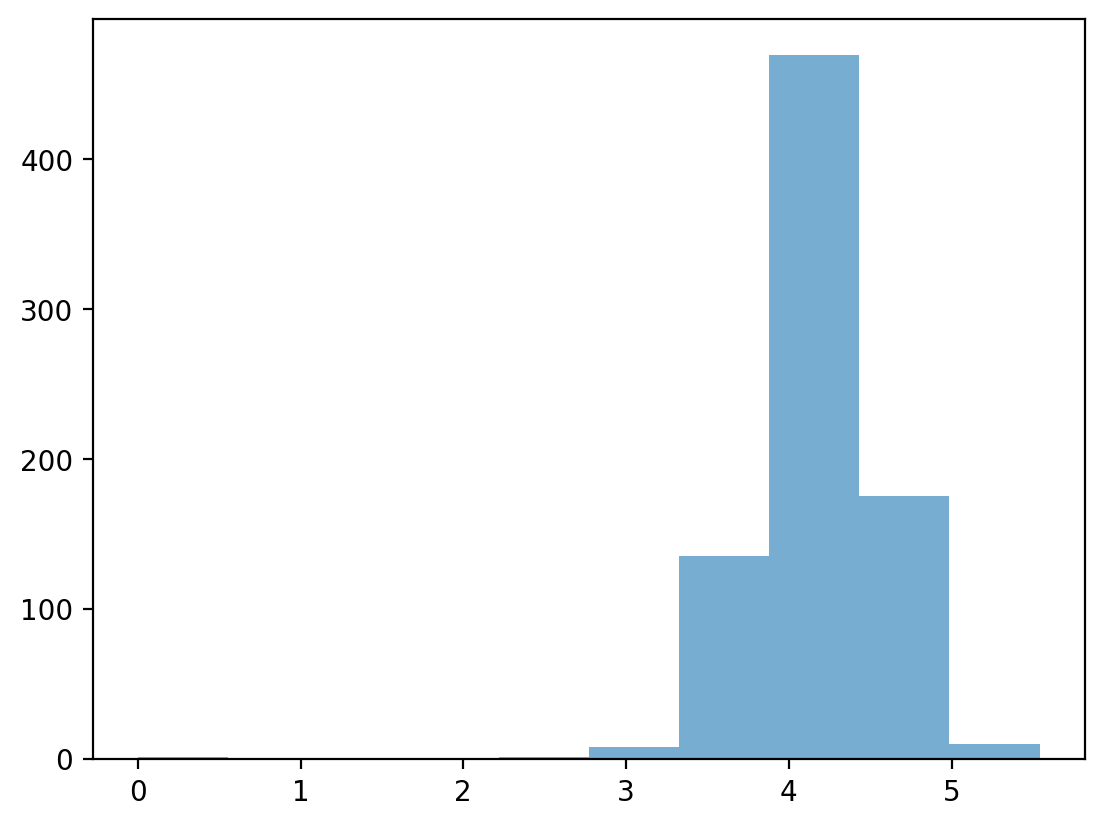

In [146]:
df_pokemon['logHP']=np.log(df_pokemon['HP'])
# powyższą linię dopisaliśmy - korzystając z logarytmowaniu

p = plt.hist(df_pokemon['logHP'], alpha = .6) # po dopisaniu linii w/w HP zmieniłem na logHP
# skośny
# są outlayery
# jest smukły
# na lewo od średniej
# prawoskoścny
# większość poniżej średniej


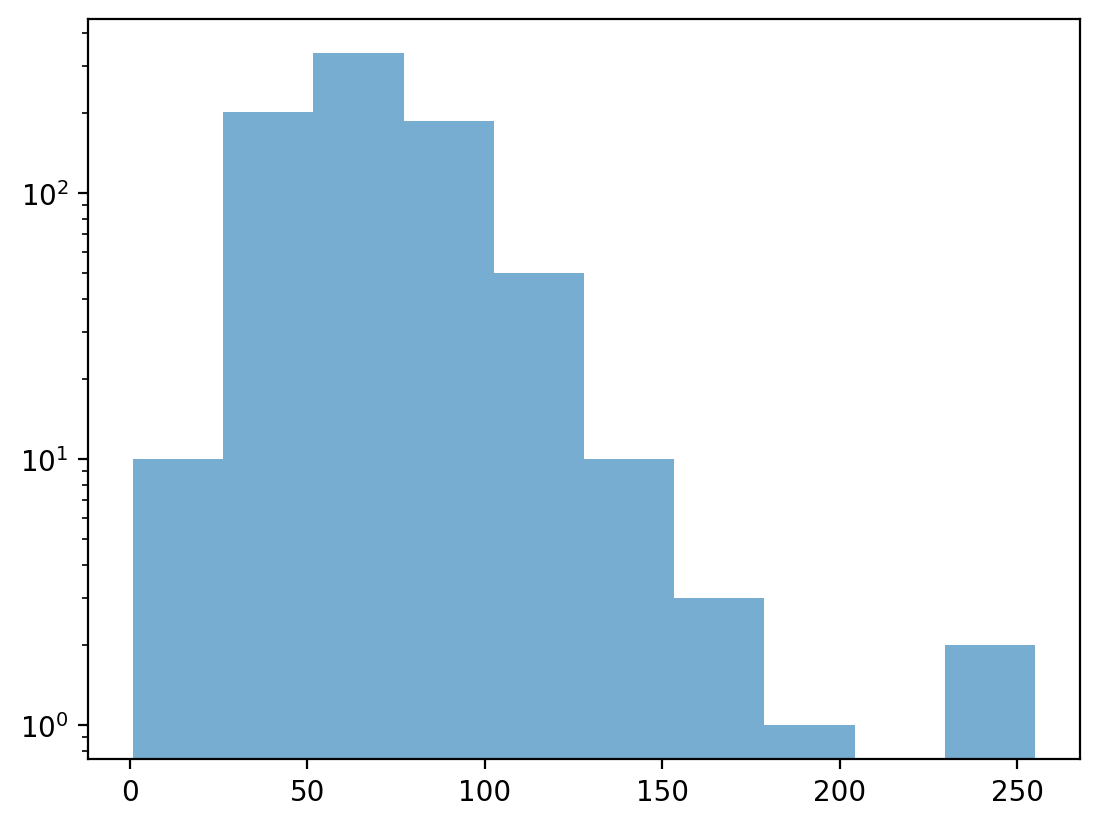

In [ ]:
p = plt.hist(df_pokemon['HP'], alpha = .6, log=True)
#zmienił skalę pionową tylko 0Y

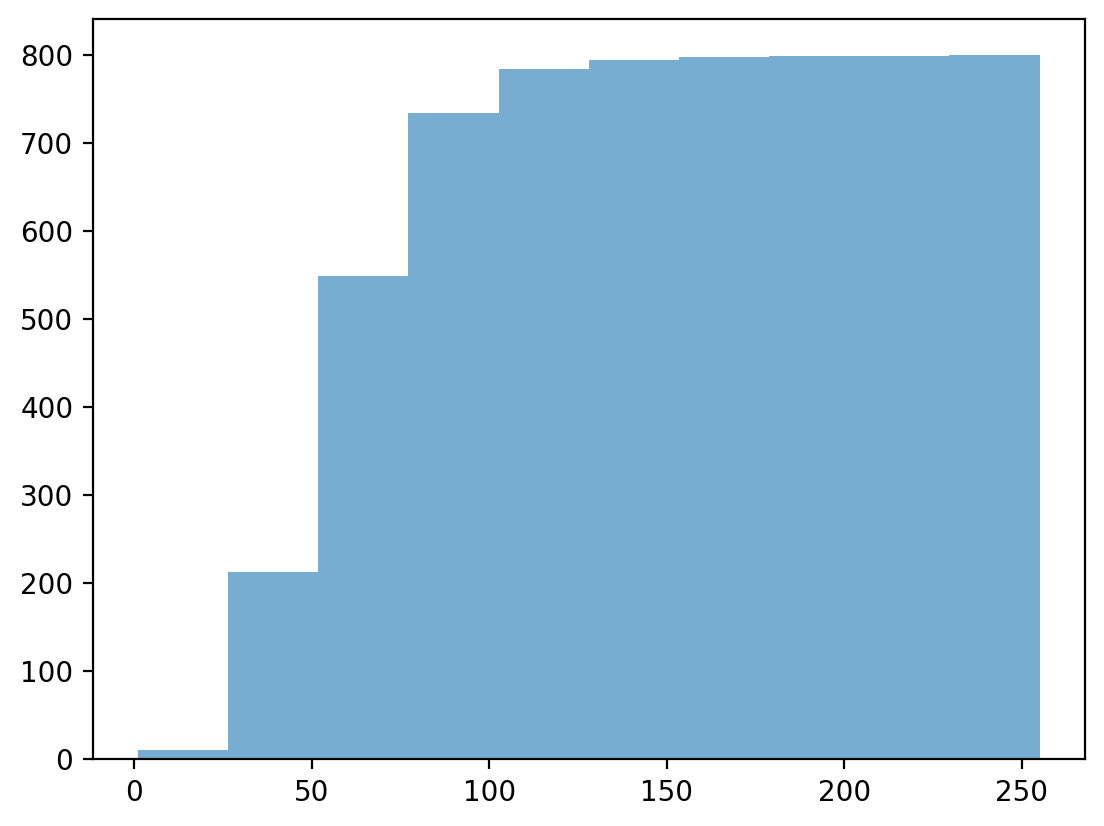

In [ ]:
p = plt.hist(df_pokemon['HP'], alpha = .6, cumulative=True)
#

In [ ]:
# tak sprawdzamy jakie soą opcje - poprzez dopisanie ?
plt.hist?

Signature:
plt.hist(
    x: 'ArrayLike | Sequence[ArrayLike]',
    bins: 'int | Sequence[float] | str | None' = None,
    *,
    range: 'tuple[float, float] | None' = None,
    density: 'bool' = False,
    weights: 'ArrayLike | None' = None,
    cumulative: 'bool | float' = False,
    bottom: 'ArrayLike | float | None' = None,
    histtype: "Literal['bar', 'barstacked', 'step', 'stepfilled']" = 'bar',
    align: "Literal['left', 'mid', 'right']" = 'mid',
    orientation: "Literal['vertical', 'horizontal']" = 'vertical',
    rwidth: 'float | None' = None,
    log: 'bool' = False,
    color: 'ColorType | Sequence[ColorType] | None' = None,
    label: 'str | Sequence[str] | None' = None,
    stacked: 'bool' = False,
    data=None,
    **kwargs,
) -> 'tuple[np.ndarray | list[np.ndarray], np.ndarray, BarContainer | Polygon | list[BarContainer | Polygon]]'
Docstring:
Compute and plot a histogram.

This method uses `numpy.histogram` to bin the data in *x* and count the
number of values in eac

#### Sprawdź się

Jak opiszesz następujący rozkład?

- Normalny czy skośny?  
- Z wartościami odstającymi czy bez?

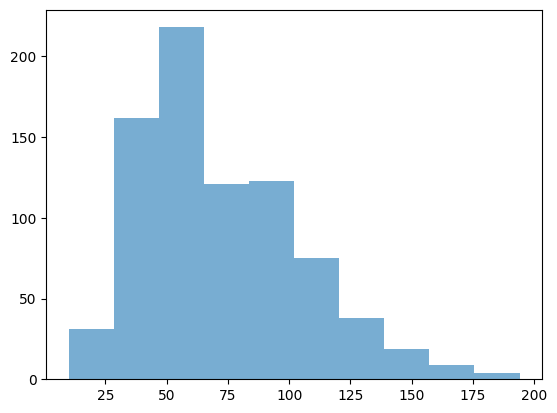

In [12]:
p = plt.hist(df_pokemon['Sp. Atk'], alpha = .6)

#### Sprawdź się

W nieco **prawoskośnym rozkładzie** (jak poniżej), co jest większe - `średnia` czy `mediana`?

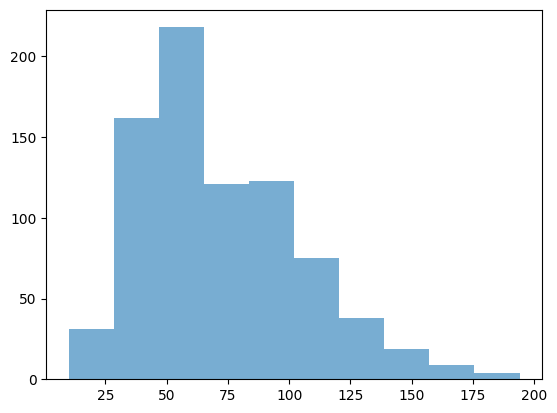

In [13]:
p = plt.hist(df_pokemon['Sp. Atk'], alpha = .6)

#### Rozwiązanie

`Średnia` jest najbardziej dotknięta **skośnością**, więc jest ciągnięta najdalej w prawo w rozkładzie prawoskośnym.

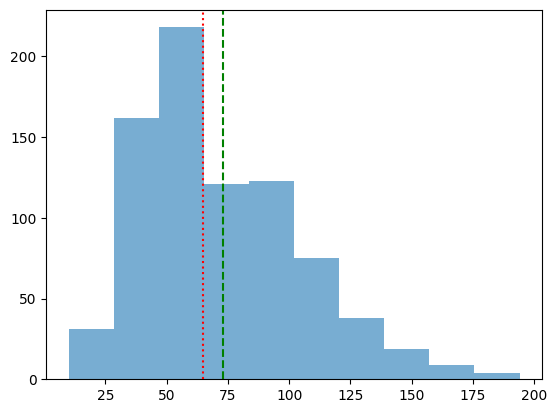

In [14]:
p = plt.hist(df_pokemon['Sp. Atk'], alpha = .6)
plt.axvline(df_pokemon['Sp. Atk'].mean(), linestyle = "dashed", color = "green");
plt.axvline(df_pokemon['Sp. Atk'].median(), linestyle = "dotted", color = "red");

### Modyfikacja naszego wykresu

- Dobra wizualizacja danych powinna również *wyjaśniać*, co jest wykreślane.
   - Wyraźnie oznaczone osie `x` i `y`, tytuł.
- Czasami możemy również chcieć dodać **nakładki**. 
   - Np. przerywaną pionową linię reprezentującą „średnią”.

#### Etykiety osi

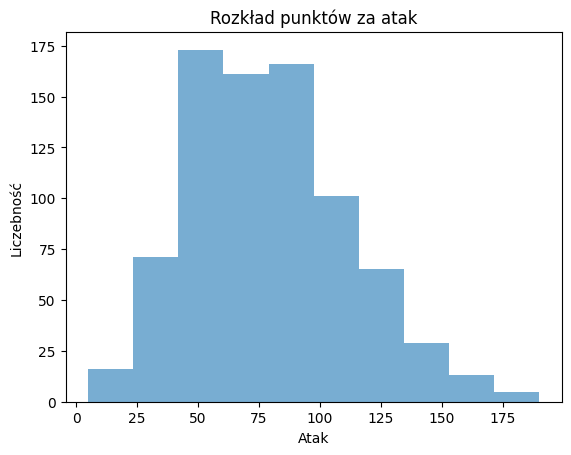

In [15]:
p = plt.hist(df_pokemon['Attack'], alpha = .6)
plt.xlabel("Atak")
plt.ylabel("Liczebność")
plt.title("Rozkład punktów za atak");

#### Linie pionowe

`plt.axvline` pozwala nam narysować pionową linię w określonej pozycji, np. `średnią` kolumny `Attack`.

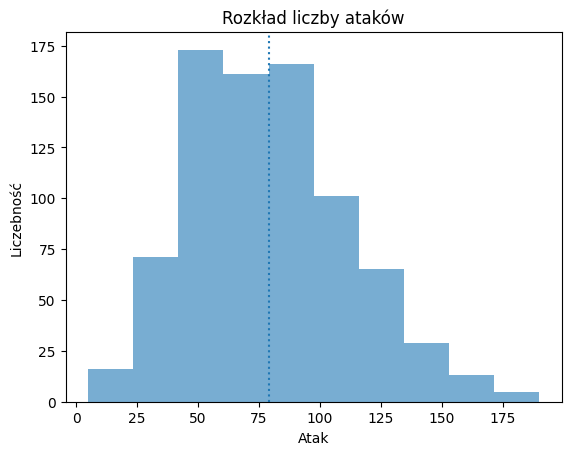

In [16]:
#Opisywanie wykresu
# 
p = plt.hist(df_pokemon['Attack'], alpha = .6)
plt.xlabel("Atak")
plt.ylabel("Liczebność")
plt.title("Rozkład liczby ataków")
plt.axvline(df_pokemon['Attack'].mean(), linestyle = "dotted");

## Histogramy z `pyplot express`

Z `pyplot express` równiez mozemy tworzyć histogramy:

In [1]:
import plotly.express as px
df = px.data.tips()
fig = px.histogram(df, x="total_bill")
fig.show()

Z `pyplot express` mozemy narysować kilka histogramów dla różnych wartości jednej kolumny:

In [2]:
import plotly.express as px
df = px.data.tips()
fig = px.histogram(df, x="total_bill", color="sex")
fig.show()

## Grupowanie histogramów

Najciekawsze jest jednak kopanie w danych głębiej - tzw. faceting - grupowanie wykresów:

In [6]:
import plotly.express as px
df = px.data.tips()
fig = px.histogram(df, x="total_bill", y="tip", color="sex", facet_row="time", facet_col="day",
       category_orders={"day": ["Thur", "Fri", "Sat", "Sun"], "time": ["Lunch", "Dinner"]})
fig.show()

## Wykresy rozrzutu

### Czym są wykresy rozrzutu?

> **Wykres rozrzutu** to wizualizacja tego, jak dwa różne rozkłady ciągłe odnoszą się do siebie.

- Każdy pojedynczy punkt reprezentuje obserwację.
- Bardzo przydatne do **eksploracyjnej analizy danych**.
   - Czy te zmienne są dodatnio czy ujemnie skorelowane?
   
Wykres rozrzutu jest wykresem **dwuwymiarowym**, tj. wyświetla co najmniej dwie zmienne.

### Wykresy rozrzutu z `matplotlib`

Możemy utworzyć scatterplot używając `plt.scatter(x, y)`, gdzie `x` i `y` to dwie zmienne, które chcemy wizualizować.

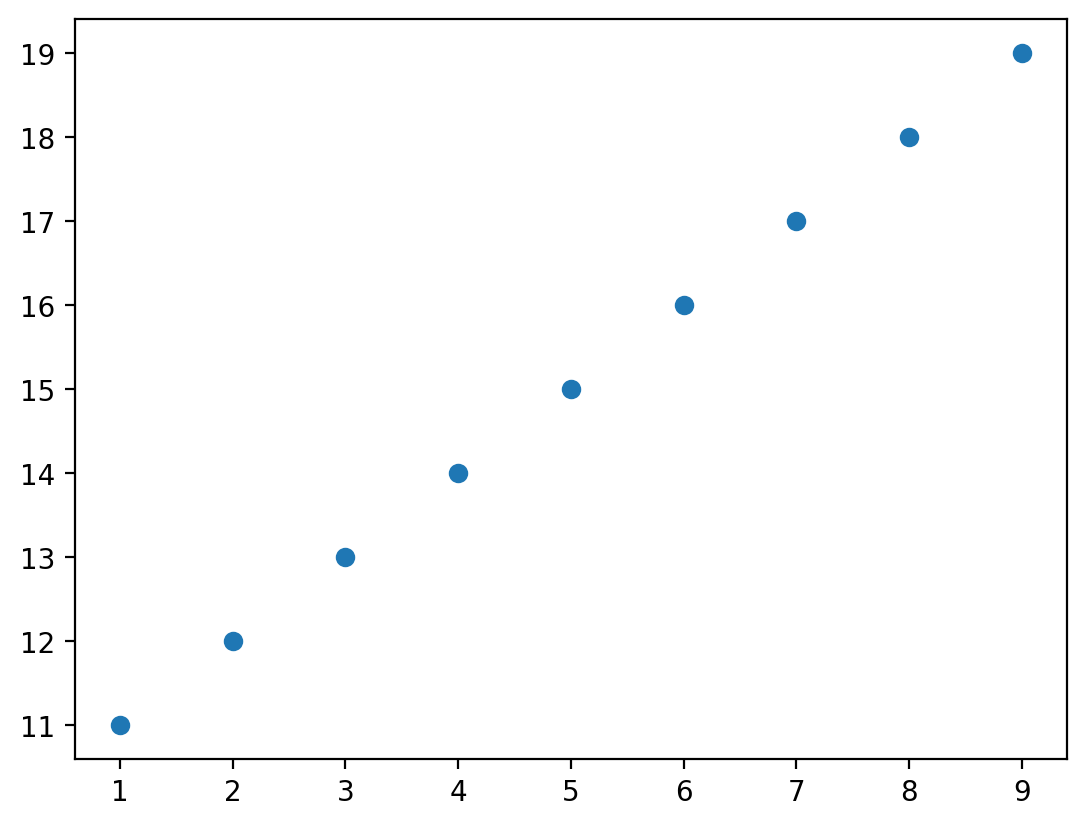

In [ ]:
x = np.arange(1, 10)
y = np.arange(11, 20)
p = plt.scatter(x, y)

#### Sprawdź się

Czy te zmienne są ze sobą powiązane? Jeśli tak, to w jaki sposób?

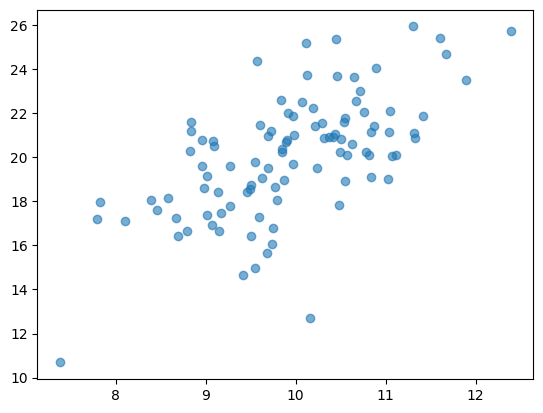

In [7]:
x = np.random.normal(loc = 10, scale = 1, size = 100)
y = x * 2 + np.random.normal(loc = 0, scale = 2, size = 100)
plt.scatter(x, y, alpha = .6);

#### Sprawdź się

Czy te zmienne są ze sobą powiązane? Jeśli tak, to w jaki sposób?

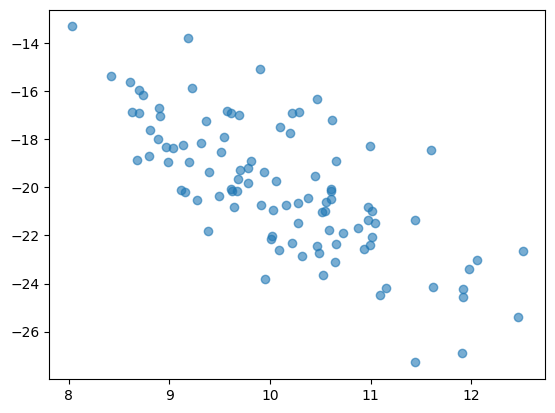

In [8]:
x = np.random.normal(loc = 10, scale = 1, size = 100)
y = -x * 2 + np.random.normal(loc = 0, scale = 2, size = 100)
plt.scatter(x, y, alpha = .6);

#### Wykrywanie zależności nieliniowych

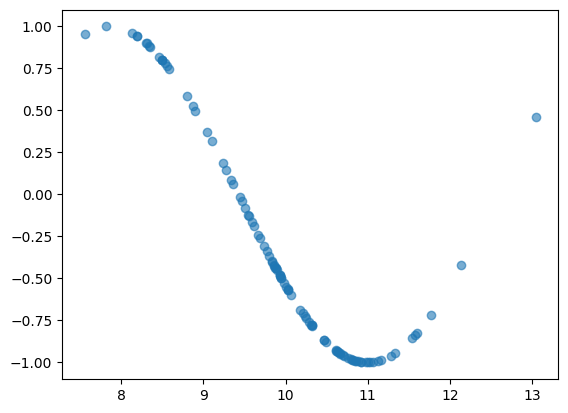

In [9]:
x = np.random.normal(loc = 10, scale = 1, size = 100)
y = np.sin(x)
plt.scatter(x, y, alpha = .6);

#### Sprawdź się

Jak moglibyśmy zwizualizować związek między `Attack` i `Speed` w naszym zbiorze danych Pokemonów?

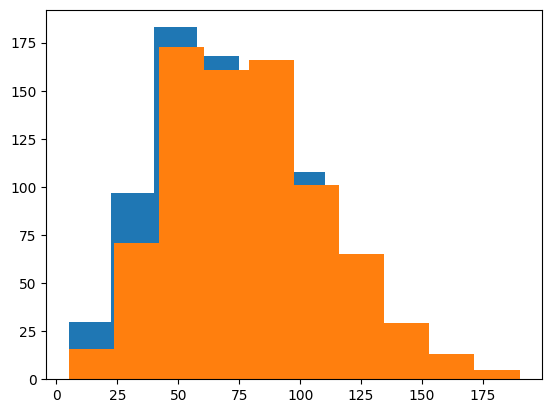

In [ ]:
p=plt.hist(df_pokemon['Speed'])
#p=plt.hist(df_pokemon['Attack'])

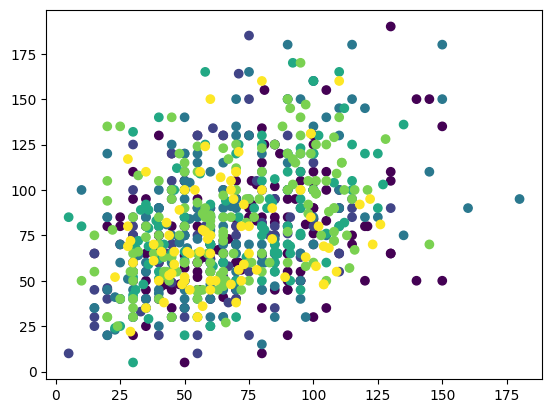

In [16]:
### Twój kod tutaj
p=plt.scatter(df_pokemon['Speed'], df_pokemon['Attack'],c=df_pokemon['Generation']);


## Wykresy rozrzutu z `pyplot express`

### Wykresy bąbelkowe

Wykresy punktowe z okrągłymi znacznikami o zmiennym rozmiarze są często nazywane wykresami bąbelkowymi. Należy pamiętać, że dane dotyczące koloru i rozmiaru są dodawane do informacji o najechaniu kursorem. Można dodać inne kolumny do danych najechania kursorem za pomocą argumentu `hover_data` w `px.scatter`.

In [ ]:
import plotly.express as px
df = px.data.iris()
fig = px.scatter(df, x="sepal_width", y="sepal_length", color="species",
                 size='petal_length', hover_data=['petal_width'])
fig.show()

#jak jest większy bąbelek to kwiatki są większe

In [26]:
import plotly.express as px

fig2 =px.scatter(df_pokemon, x="Speed", y="Attack", color="Legendary", size='Generation',
                 hover_data=['Name', 'HP', 'Sp. Atk', 'Sp. Def'])
fig2.show()

Kolor może być ciągły, jak poniżej, lub dyskretny/kategorialny, jak powyżej.

In [ ]:
df = px.data.iris()
fig = px.scatter(df, x="sepal_width", y="sepal_length", color='petal_length')
fig.show()

Argument symbolu może być również mapowany na kolumnę. Dostępna jest [szeroka gama symboli](https://plotly.com/python/marker-style/).

In [ ]:
df = px.data.iris()
fig = px.scatter(df, x="sepal_width", y="sepal_length", color="species", symbol="species")
fig.show()

## Grupowane wykresy rozrzutu

Wykresy rozrzutu wspierają grupowanie - tzw. faceting.

In [ ]:
df = px.data.tips()
fig = px.scatter(df, x="total_bill", y="tip", color="smoker", facet_col="sex", facet_row="time")
fig.show()

## Dodawanie linii



Na wykres rozrzutu nałozyć mozna oszacowaną funkcję liniową:

In [ ]:
df = px.data.tips()
fig = px.scatter(df, x="total_bill", y="tip", trendline="ols")
fig.show()

## Wykresy słupkowe

### Czym jest barplot?

> **Wykres słupkowy** wizualizuje związek pomiędzy jedną *zmienną ciągłą* a *zmienną kategorialną*.

- *Wysokość* każdego słupka zazwyczaj wskazuje średnią zmiennej ciągłej.
- Każdy słupek reprezentuje inny *poziom* zmiennej kategorialnej.

Wykres słupkowy jest wykresem **dwuwymiarowym**, tj. wyświetla co najmniej dwie zmienne.

### Wykresy słupkowe z `matplotlib`

`plt.bar` może być użyty do stworzenia **wykresu słupkowego** naszych danych.

- Na przykład, średni `Attack` według `Legendarnego` statusu.
- Jednak najpierw musimy użyć `groupby`, aby obliczyć średnią `Attack` na poziom.

#### Krok 1: Wykorzystanie `groupby`

In [ ]:
summary = df_pokemon[['Legendary', 'Attack']].groupby("Legendary").mean().reset_index()
summary

,Legendary,Attack
0,False,75.669388
1,True,116.676923


In [ ]:
### Zmiana "Legendary" na str
summary['Legendary'] = summary['Legendary'].apply(lambda x: str(x))
summary

,Legendary,Attack
0,False,75.669388
1,True,116.676923


#### Krok 2: Przekazanie wartości na `plt.bar`

**Sprawdź się**:

- Czego dowiadujemy się z tego wykresu?  
- Czego brakuje w tej opowieści?

Text(0, 0.5, 'Atak')

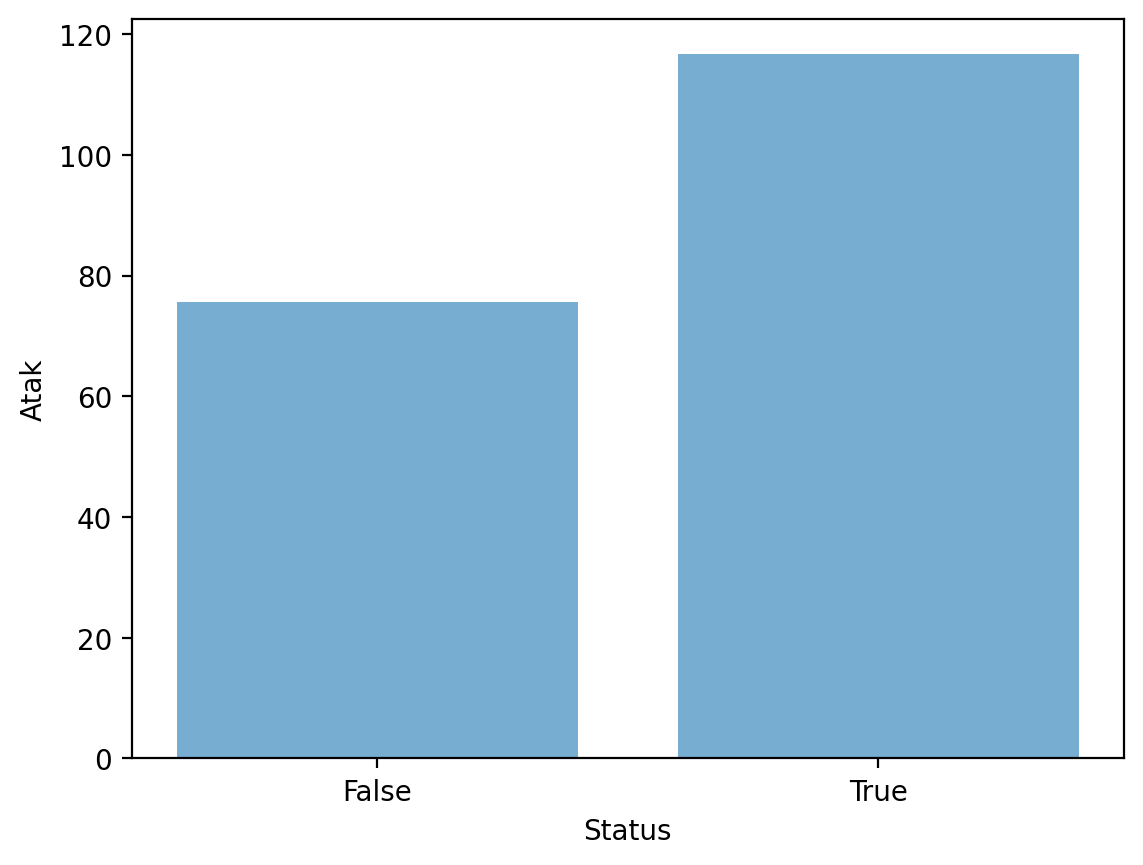

In [ ]:
plt.bar(x = summary['Legendary'],
       height = summary['Attack'],
       alpha = .6)
plt.xlabel("Status")
plt.ylabel("Atak")

## Plotly express

Plotly Express to łatwy w użyciu, wysokopoziomowy interfejs do Plotly, który działa na różnych typach danych i tworzy łatwe do stylizacji wykresy.

Dzięki px.bar każdy wiersz ramki DataFrame jest reprezentowany jako prostokątny znak. Aby zagregować wiele punktów danych w ten sam prostokątny znak, należy zapoznać się z dokumentacją histogramu.

W poniższym przykładzie jest tylko jeden wiersz danych na rok, więc wyświetlany jest jeden słupek na rok.

In [ ]:
import plotly.express as px
data_canada = px.data.gapminder().query("country == 'Canada'")
fig = px.bar(data_canada, x='year', y='pop')
fig.show()

## Wykresy słupkowe z danymi w formacie `long`

Dane w długim formacie mają jeden wiersz na obserwację i jedną kolumnę na zmienną. Jest to odpowiednie do przechowywania i wyświetlania danych wielowymiarowych, tj. o wymiarze większym niż 2. Format ten jest czasami nazywany „uporządkowanym”.

Aby dowiedzieć się więcej o tym, jak dostarczyć konkretną formę danych zorientowanych na kolumny do funkcji 2D-Cartesian Plotly Express, takich jak px.bar, zobacz dokumentację [Plotly Express Wide-Form Support in Python](https://plotly.com/python/wide-form/).

In [ ]:
long_df = px.data.medals_long()

fig = px.bar(long_df, x="nation", y="count", color="medal", title="Dane w formacie long")
fig.show()

Podejrzyjmy dane:

In [ ]:
long_df

,nation,medal,count
0,South Korea,gold,24
1,China,gold,10
2,Canada,gold,9
3,South Korea,silver,13
4,China,silver,15
5,Canada,silver,12
6,South Korea,bronze,11
7,China,bronze,8
8,Canada,bronze,12


## Wykresy słupkowe z danymi w formacie `wide`

Dane w szerokim formacie mają jeden wiersz na wartość jednej z pierwszych zmiennych i jedną kolumnę na wartość drugiej zmiennej. 

Jest to odpowiednie do przechowywania i wyświetlania danych dwuwymiarowych.

In [ ]:
wide_df = px.data.medals_wide()

fig = px.bar(wide_df, x="nation", y=["gold", "silver", "bronze"], title="Dane w formacie wide")
fig.show()

Zobaczmy jak wyglądają dane w formacie `wide`:

In [ ]:
wide_df

,nation,gold,silver,bronze
0,South Korea,24,13,11
1,China,10,15,8
2,Canada,9,12,12


### Kolorowane słupki 

Wykres słupkowy można dostosować za pomocą argumentów słów kluczowych, na przykład w celu użycia koloru ciągłego, jak poniżej, lub koloru dyskretnego, jak powyżej.

In [ ]:
df = px.data.gapminder().query("country == 'Poland'")
fig = px.bar(df, x='year', y='pop',
             hover_data=['lifeExp', 'gdpPercap'], color='lifeExp',
             labels={'pop':'ludność w Polsce'}, height=400)
fig.show()

In [ ]:
df = px.data.gapminder().query("continent == 'Oceania'")
fig = px.bar(df, x='year', y='pop',
             hover_data=['lifeExp', 'gdpPercap'], color='country',
             labels={'pop':'population of Canada'}, height=400)
fig.show()

### Stos vs grupowane słupki

Gdy kilka wierszy ma tę samą wartość x (tutaj Kobieta lub Mężczyzna), prostokąty są domyślnie ułożone jeden na drugim.

In [ ]:
df = px.data.tips()
fig = px.bar(df, x="sex", y="total_bill", color='time')
fig.show()

Domyślne zachowanie skumulowanego wykresu słupkowego można zmienić na zgrupowane (znane również jako klastrowane) za pomocą argumentu barmode:

In [ ]:
df = px.data.tips()
fig = px.bar(df, x="sex", y="total_bill",
             color='smoker', barmode='group',
             height=400)
fig.show()

## Grupowanie wykresów słupkowych

Użycie argumentów słowa kluczowego `facet_row` (lub `facet_col`), utworzy nam grupowane subploty, w których różne wiersze (lub kolumny) odpowiadają różnym wartościom kolumny ramki danych określonej w `facet_row`.

In [ ]:
df = px.data.tips()
fig = px.bar(df, x="sex", y="total_bill", color="smoker", barmode="group",
             facet_row="time", facet_col="day",
             category_orders={"day": ["Thur", "Fri", "Sat", "Sun"],
                              "time": ["Lunch", "Dinner"]})
fig.show()